# Question 1

Text preprocessing on a paragraph about cricket.

In [1]:
import re
import nltk
from nltk import FreqDist
from nltk.corpus import stopwords
from nltk.tokenize import sent_tokenize, word_tokenize

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)

STOP = set(stopwords.words("english"))

paragraph = (
    "Cricket is the sport I enjoy watching and playing the most. "
    "A single match can change direction in just one over, which keeps every fan on the edge of their seat. "
    "I still remember the 2011 World Cup final, when the whole country celebrated after the winning six! "
    "Good batsmen build their innings patiently, while fast bowlers try to break the stumps with pace and swing. "
    "Fielding is equally important, because one dropped catch can cost a team the match. "
    "Playing cricket with my friends every weekend has taught me teamwork, patience and discipline."
)
paragraph

'Cricket is the sport I enjoy watching and playing the most. A single match can change direction in just one over, which keeps every fan on the edge of their seat. I still remember the 2011 World Cup final, when the whole country celebrated after the winning six! Good batsmen build their innings patiently, while fast bowlers try to break the stumps with pace and swing. Fielding is equally important, because one dropped catch can cost a team the match. Playing cricket with my friends every weekend has taught me teamwork, patience and discipline.'

### 1. Lowercase and remove punctuation using `re`

In [2]:
cleaned = re.sub(r"[^\w\s]", "", paragraph.lower())
cleaned

'cricket is the sport i enjoy watching and playing the most a single match can change direction in just one over which keeps every fan on the edge of their seat i still remember the 2011 world cup final when the whole country celebrated after the winning six good batsmen build their innings patiently while fast bowlers try to break the stumps with pace and swing fielding is equally important because one dropped catch can cost a team the match playing cricket with my friends every weekend has taught me teamwork patience and discipline'

### 2. Tokenize into sentences and words

In [3]:
sentences = sent_tokenize(paragraph)
for i, sentence in enumerate(sentences, start=1):
    print(i, sentence)

1 Cricket is the sport I enjoy watching and playing the most.
2 A single match can change direction in just one over, which keeps every fan on the edge of their seat.
3 I still remember the 2011 World Cup final, when the whole country celebrated after the winning six!
4 Good batsmen build their innings patiently, while fast bowlers try to break the stumps with pace and swing.
5 Fielding is equally important, because one dropped catch can cost a team the match.
6 Playing cricket with my friends every weekend has taught me teamwork, patience and discipline.


In [4]:
words = word_tokenize(cleaned)
print(len(words), "words")
words

94 words


['cricket',
 'is',
 'the',
 'sport',
 'i',
 'enjoy',
 'watching',
 'and',
 'playing',
 'the',
 'most',
 'a',
 'single',
 'match',
 'can',
 'change',
 'direction',
 'in',
 'just',
 'one',
 'over',
 'which',
 'keeps',
 'every',
 'fan',
 'on',
 'the',
 'edge',
 'of',
 'their',
 'seat',
 'i',
 'still',
 'remember',
 'the',
 '2011',
 'world',
 'cup',
 'final',
 'when',
 'the',
 'whole',
 'country',
 'celebrated',
 'after',
 'the',
 'winning',
 'six',
 'good',
 'batsmen',
 'build',
 'their',
 'innings',
 'patiently',
 'while',
 'fast',
 'bowlers',
 'try',
 'to',
 'break',
 'the',
 'stumps',
 'with',
 'pace',
 'and',
 'swing',
 'fielding',
 'is',
 'equally',
 'important',
 'because',
 'one',
 'dropped',
 'catch',
 'can',
 'cost',
 'a',
 'team',
 'the',
 'match',
 'playing',
 'cricket',
 'with',
 'my',
 'friends',
 'every',
 'weekend',
 'has',
 'taught',
 'me',
 'teamwork',
 'patience',
 'and',
 'discipline']

### 3. `split()` vs `word_tokenize()`

In [5]:
split_tokens = paragraph.split()
nltk_tokens = word_tokenize(paragraph)

print("split()        :", len(split_tokens), "tokens")
print("word_tokenize():", len(nltk_tokens), "tokens\n")
print("Only in split()        :", sorted(set(split_tokens) - set(nltk_tokens)))
print("Only in word_tokenize():", sorted(set(nltk_tokens) - set(split_tokens)))

split()        : 94 tokens
word_tokenize(): 105 tokens

Only in split()        : ['discipline.', 'final,', 'important,', 'match.', 'most.', 'over,', 'patiently,', 'seat.', 'six!', 'swing.', 'teamwork,']
Only in word_tokenize(): ['!', ',', '.', 'discipline', 'final', 'important', 'most', 'over', 'patiently', 'seat', 'six', 'swing', 'teamwork']


**Difference:** `split()` only cuts on whitespace, so punctuation stays glued to the word (`discipline.`, `final,`, `six!`) and the same word appears as different tokens. `word_tokenize()` separates punctuation into its own tokens (`.`, `,`, `!`) and gives the clean words back. That is why `word_tokenize()` returns 105 tokens against 94 for `split()`: it adds one token for each of the 11 punctuation marks.

### 4. Remove stopwords

In [6]:
filtered = [w for w in words if w not in STOP]
print(len(words), "->", len(filtered), "words")
filtered

94 -> 56 words


['cricket',
 'sport',
 'enjoy',
 'watching',
 'playing',
 'single',
 'match',
 'change',
 'direction',
 'one',
 'keeps',
 'every',
 'fan',
 'edge',
 'seat',
 'still',
 'remember',
 '2011',
 'world',
 'cup',
 'final',
 'whole',
 'country',
 'celebrated',
 'winning',
 'six',
 'good',
 'batsmen',
 'build',
 'innings',
 'patiently',
 'fast',
 'bowlers',
 'try',
 'break',
 'stumps',
 'pace',
 'swing',
 'fielding',
 'equally',
 'important',
 'one',
 'dropped',
 'catch',
 'cost',
 'team',
 'match',
 'playing',
 'cricket',
 'friends',
 'every',
 'weekend',
 'taught',
 'teamwork',
 'patience',
 'discipline']

### 5. Word frequency distribution (without stopwords)

[('cricket', 2), ('playing', 2), ('match', 2), ('one', 2), ('every', 2), ('sport', 1), ('enjoy', 1), ('watching', 1), ('single', 1), ('change', 1)]


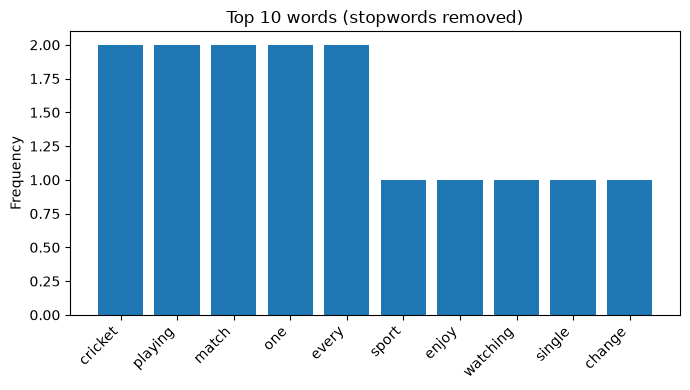

In [7]:
import matplotlib.pyplot as plt

freq = FreqDist(filtered)
print(freq.most_common(10))

top = freq.most_common(10)
plt.figure(figsize=(7, 4))
plt.bar([w for w, _ in top], [c for _, c in top])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Frequency")
plt.title("Top 10 words (stopwords removed)")
plt.tight_layout()
plt.show()

# Question 2

Stemming and lemmatization on the same paragraph.

### 1. Alphabet-only words using `re.findall()`

In [8]:
alpha_words = re.findall(r"[A-Za-z]+", paragraph.lower())
print(len(alpha_words), "words")
alpha_words

93 words


['cricket',
 'is',
 'the',
 'sport',
 'i',
 'enjoy',
 'watching',
 'and',
 'playing',
 'the',
 'most',
 'a',
 'single',
 'match',
 'can',
 'change',
 'direction',
 'in',
 'just',
 'one',
 'over',
 'which',
 'keeps',
 'every',
 'fan',
 'on',
 'the',
 'edge',
 'of',
 'their',
 'seat',
 'i',
 'still',
 'remember',
 'the',
 'world',
 'cup',
 'final',
 'when',
 'the',
 'whole',
 'country',
 'celebrated',
 'after',
 'the',
 'winning',
 'six',
 'good',
 'batsmen',
 'build',
 'their',
 'innings',
 'patiently',
 'while',
 'fast',
 'bowlers',
 'try',
 'to',
 'break',
 'the',
 'stumps',
 'with',
 'pace',
 'and',
 'swing',
 'fielding',
 'is',
 'equally',
 'important',
 'because',
 'one',
 'dropped',
 'catch',
 'can',
 'cost',
 'a',
 'team',
 'the',
 'match',
 'playing',
 'cricket',
 'with',
 'my',
 'friends',
 'every',
 'weekend',
 'has',
 'taught',
 'me',
 'teamwork',
 'patience',
 'and',
 'discipline']

### 2. Remove stopwords

In [9]:
alpha_filtered = [w for w in alpha_words if w not in STOP]
print(len(alpha_filtered), "words")
alpha_filtered

55 words


['cricket',
 'sport',
 'enjoy',
 'watching',
 'playing',
 'single',
 'match',
 'change',
 'direction',
 'one',
 'keeps',
 'every',
 'fan',
 'edge',
 'seat',
 'still',
 'remember',
 'world',
 'cup',
 'final',
 'whole',
 'country',
 'celebrated',
 'winning',
 'six',
 'good',
 'batsmen',
 'build',
 'innings',
 'patiently',
 'fast',
 'bowlers',
 'try',
 'break',
 'stumps',
 'pace',
 'swing',
 'fielding',
 'equally',
 'important',
 'one',
 'dropped',
 'catch',
 'cost',
 'team',
 'match',
 'playing',
 'cricket',
 'friends',
 'every',
 'weekend',
 'taught',
 'teamwork',
 'patience',
 'discipline']

### 3. Stemming with `PorterStemmer`

In [10]:
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

porter = PorterStemmer()
stemmed = [porter.stem(w) for w in alpha_filtered]
stemmed

['cricket',
 'sport',
 'enjoy',
 'watch',
 'play',
 'singl',
 'match',
 'chang',
 'direct',
 'one',
 'keep',
 'everi',
 'fan',
 'edg',
 'seat',
 'still',
 'rememb',
 'world',
 'cup',
 'final',
 'whole',
 'countri',
 'celebr',
 'win',
 'six',
 'good',
 'batsmen',
 'build',
 'inning',
 'patient',
 'fast',
 'bowler',
 'tri',
 'break',
 'stump',
 'pace',
 'swing',
 'field',
 'equal',
 'import',
 'one',
 'drop',
 'catch',
 'cost',
 'team',
 'match',
 'play',
 'cricket',
 'friend',
 'everi',
 'weekend',
 'taught',
 'teamwork',
 'patienc',
 'disciplin']

### 4. Lemmatization with `WordNetLemmatizer`

In [11]:
lemmatizer = WordNetLemmatizer()


def wordnet_pos(tag):
    return {"J": wordnet.ADJ, "V": wordnet.VERB, "R": wordnet.ADV}.get(tag[0], wordnet.NOUN)


lemmatized = [lemmatizer.lemmatize(w, wordnet_pos(tag)) for w, tag in nltk.pos_tag(alpha_filtered)]
lemmatized

['cricket',
 'sport',
 'enjoy',
 'watch',
 'play',
 'single',
 'match',
 'change',
 'direction',
 'one',
 'keep',
 'every',
 'fan',
 'edge',
 'seat',
 'still',
 'remember',
 'world',
 'cup',
 'final',
 'whole',
 'country',
 'celebrate',
 'win',
 'six',
 'good',
 'batsman',
 'build',
 'inning',
 'patiently',
 'fast',
 'bowler',
 'try',
 'break',
 'stumps',
 'pace',
 'swing',
 'field',
 'equally',
 'important',
 'one',
 'drop',
 'catch',
 'cost',
 'team',
 'match',
 'play',
 'cricket',
 'friend',
 'every',
 'weekend',
 'taught',
 'teamwork',
 'patience',
 'discipline']

### 5. Comparison

In [12]:
import pandas as pd

comparison = pd.DataFrame({"Word": alpha_filtered, "Stem": stemmed, "Lemma": lemmatized})
differ = comparison[comparison["Stem"] != comparison["Lemma"]].drop_duplicates()
print(f"{len(differ)} of {len(comparison)} words differ\n")
print(differ.to_string(index=False))

16 of 55 words differ

      Word      Stem      Lemma
    single     singl     single
    change     chang     change
 direction    direct  direction
     every     everi      every
      edge       edg       edge
  remember    rememb   remember
   country   countri    country
celebrated    celebr  celebrate
   batsmen   batsmen    batsman
 patiently   patient  patiently
       try       tri        try
    stumps     stump     stumps
   equally     equal    equally
 important    import  important
  patience   patienc   patience
discipline disciplin discipline


**Stemming vs lemmatization:** 16 of the 55 words differ.

- Porter cuts suffixes with fixed rules, so it often returns non-words: `singl`, `everi`, `countri`, `tri`, `patienc`, `disciplin`.
- The lemmatizer returns valid dictionary words (`celebrate`, `batsman`, `try`, `discipline`). It can leave a form unchanged when the POS tag does not call for a change, as with `patiently` and `stumps`.

**When to prefer which:**

- Prefer **stemming** when speed matters and the stems are only used internally, for example search engines, indexing and large-scale text classification, where `play`, `playing` and `played` just need to match each other.
- Prefer **lemmatization** when the output must be readable or the meaning matters, for example chatbots, sentiment analysis, topic keywords or anything shown to a user. It is slower and needs POS tags.

# Question 3

Bag of Words and TF-IDF on three short texts.

In [13]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

texts = [
    "The new phone has a brilliant display and an amazing camera, but the phone battery drains quickly.",
    "India won the cricket match by five wickets after a brilliant century from the captain. The captain was named player of the match.",
    "The restaurant served delicious pasta, and the staff were friendly, but the service was slow. The pasta was worth the wait.",
]

### 1. Bag of Words with `CountVectorizer`

In [14]:
count_vec = CountVectorizer(stop_words="english")
bow = count_vec.fit_transform(texts)

bow_df = pd.DataFrame(bow.toarray(), columns=count_vec.get_feature_names_out(), index=["Text 1", "Text 2", "Text 3"])
bow_df

,amazing,battery,brilliant,camera,captain,century,cricket,delicious,display,drains,...,quickly,restaurant,served,service,slow,staff,wait,wickets,won,worth
Text 1,1,1,1,1,0,0,0,0,1,1,...,1,0,0,0,0,0,0,0,0,0
Text 2,0,0,1,0,2,1,1,0,0,0,...,0,0,0,0,0,0,0,1,1,0
Text 3,0,0,0,0,0,0,0,1,0,0,...,0,1,1,1,1,1,1,0,0,1


### 2. TF-IDF with `TfidfVectorizer`

In [15]:
tfidf_vec = TfidfVectorizer(stop_words="english")
tfidf = tfidf_vec.fit_transform(texts)

tfidf_df = pd.DataFrame(tfidf.toarray(), columns=tfidf_vec.get_feature_names_out(), index=["Text 1", "Text 2", "Text 3"])
tfidf_df.round(3)

,amazing,battery,brilliant,camera,captain,century,cricket,delicious,display,drains,...,quickly,restaurant,served,service,slow,staff,wait,wickets,won,worth
Text 1,0.294,0.294,0.224,0.294,0.000,0.000,0.000,0.000,0.294,0.294,...,0.294,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Text 2,0.000,0.000,0.193,0.000,0.507,0.253,0.253,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.253,0.253,0.000
Text 3,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.277,0.000,0.000,...,0.000,0.277,0.277,0.277,0.277,0.277,0.277,0.000,0.000,0.277


### 3. Top 3 keywords of each text

In [16]:
for name, row in tfidf_df.iterrows():
    print(name, "->", row.nlargest(3).round(3).to_dict())

Text 1 -> {'phone': 0.588, 'amazing': 0.294, 'battery': 0.294}
Text 2 -> {'captain': 0.507, 'match': 0.507, 'century': 0.253}
Text 3 -> {'pasta': 0.555, 'delicious': 0.277, 'friendly': 0.277}


**Interpretation:** TF-IDF gives a high score to words that are frequent in one text and rare in the others.

- **Text 1** (phone review): `phone` (0.588) is the top keyword because it appears twice and in no other text. `amazing` and `battery` follow.
- **Text 2** (cricket match): `captain` and `match` (0.507 each) are repeated and unique to this text, then `century`. They describe the topic well.
- **Text 3** (restaurant): `pasta` (0.555) leads, followed by `delicious` and `friendly`.
- `brilliant` appears in both Text 1 and Text 2, so its IDF is lower and it does not reach any top 3.
- With only three short texts, the second and third places are ties between words that occur once, so the order between them is arbitrary. Bag of Words only counts words, while TF-IDF separates the topic words from common ones.

# Question 4

Similarity between two technology descriptions.

In [17]:
text_ai = (
    "Artificial intelligence lets computers learn from data and make decisions. "
    "Machine learning models find patterns in large datasets and improve with experience. "
    "AI is used in healthcare, finance and education to automate work and predict outcomes. "
    "Systems such as chatbots and image recognition can now understand language and pictures."
)

text_blockchain = (
    "Blockchain is a distributed ledger that records transactions across many computers. "
    "Each block is linked to the previous one using cryptography, so the data cannot be changed easily. "
    "Blockchain is used in finance, supply chains and healthcare to keep records secure and transparent. "
    "Cryptocurrencies such as Bitcoin run on this technology without any central authority."
)

### 1. Preprocess and tokenize

In [18]:
def preprocess(text):
    tokens = word_tokenize(re.sub(r"[^\w\s]", "", text.lower()))
    tokens = [t for t in tokens if t not in STOP]
    return [lemmatizer.lemmatize(t) for t in tokens]


tokens_ai = preprocess(text_ai)
tokens_blockchain = preprocess(text_blockchain)

print("AI        :", tokens_ai)
print("Blockchain:", tokens_blockchain)

AI        : ['artificial', 'intelligence', 'let', 'computer', 'learn', 'data', 'make', 'decision', 'machine', 'learning', 'model', 'find', 'pattern', 'large', 'datasets', 'improve', 'experience', 'ai', 'used', 'healthcare', 'finance', 'education', 'automate', 'work', 'predict', 'outcome', 'system', 'chatbots', 'image', 'recognition', 'understand', 'language', 'picture']
Blockchain: ['blockchain', 'distributed', 'ledger', 'record', 'transaction', 'across', 'many', 'computer', 'block', 'linked', 'previous', 'one', 'using', 'cryptography', 'data', 'changed', 'easily', 'blockchain', 'used', 'finance', 'supply', 'chain', 'healthcare', 'keep', 'record', 'secure', 'transparent', 'cryptocurrencies', 'bitcoin', 'run', 'technology', 'without', 'central', 'authority']


### 2a. Jaccard similarity using sets

In [19]:
set_ai, set_blockchain = set(tokens_ai), set(tokens_blockchain)
common = set_ai & set_blockchain

jaccard = len(common) / len(set_ai | set_blockchain)
print("Common words :", sorted(common))
print("Jaccard      :", round(jaccard, 4))

Common words : ['computer', 'data', 'finance', 'healthcare', 'used']
Jaccard      : 0.0833


### 2b. Cosine similarity using `TfidfVectorizer`

In [20]:
from sklearn.metrics.pairwise import cosine_similarity

processed = [" ".join(tokens_ai), " ".join(tokens_blockchain)]
vectors = TfidfVectorizer().fit_transform(processed)

cosine = cosine_similarity(vectors[0], vectors[1])[0][0]
print("Cosine:", round(cosine, 4))

Cosine: 0.0769


**Analysis:** The two texts share only 5 of their 60 distinct words (`computer`, `data`, `finance`, `healthcare`, `used`), so both metrics are low: Jaccard is 0.0833 and cosine is 0.0769.

- **Jaccard** only asks how many words are shared. It ignores how often a word occurs, and it treats a generic word like `used` the same as a meaningful one.
- **Cosine with TF-IDF** accounts for word frequency and down-weights words that appear in both texts, so it is slightly lower. It reflects that the overlap is made of generic words, not of the main topic words (`blockchain`, `ledger`, `machine`, `learning`).

Cosine similarity gives better insight here, and for longer texts in general. Jaccard is still useful because it shows exactly which words overlap. Both only compare exact words, so neither sees that the two technologies are conceptually related through `records`/`data` or `finance`/`healthcare` use.

# Question 5

Sentiment analysis of product reviews.

In [21]:
from textblob import TextBlob

reviews = [
    "The headphones sound fantastic and the battery lasts all day. Totally worth the price!",
    "Terrible service. The delivery was late and the package arrived damaged.",
    "The laptop has 8 GB of RAM and a 14 inch screen.",
    "I love this keyboard, the keys feel smooth and the build quality is excellent.",
    "Very disappointing. The screen stopped working after two weeks and support was useless.",
    "The room was clean and the staff were friendly and helpful. A wonderful stay!",
    "The product arrived on Monday in a standard box.",
    "Great value for money, the camera is amazing and the display is beautiful.",
]

### 1. Polarity and subjectivity

In [22]:
def classify(polarity):
    if polarity > 0.1:
        return "Positive"
    if polarity < -0.1:
        return "Negative"
    return "Neutral"


rows = []
for review in reviews:
    sentiment = TextBlob(review).sentiment
    rows.append({
        "Review": review[:55] + "...",
        "Polarity": round(sentiment.polarity, 3),
        "Subjectivity": round(sentiment.subjectivity, 3),
        "Label": classify(sentiment.polarity),
    })

sentiment_df = pd.DataFrame(rows)
print(sentiment_df.to_string(index=False))

                                                    Review  Polarity  Subjectivity    Label
The headphones sound fantastic and the battery lasts al...     0.392         0.467 Positive
Terrible service. The delivery was late and the package...    -0.650         0.800 Negative
       The laptop has 8 GB of RAM and a 14 inch screen....     0.000         0.000  Neutral
I love this keyboard, the keys feel smooth and the buil...     0.633         0.700 Positive
Very disappointing. The screen stopped working after tw...    -0.640         0.555 Negative
The room was clean and the staff were friendly and help...     0.581         0.733 Positive
       The product arrived on Monday in a standard box....     0.000         0.000  Neutral
Great value for money, the camera is amazing and the di...     0.750         0.883 Positive


### 2. Classification summary

In [23]:
sentiment_df["Label"].value_counts()

Label
Positive    4
Negative    2
Neutral     2
Name: count, dtype: int64

Polarity above 0.1 is Positive, below -0.1 is Negative, and anything in between is Neutral.

### 3. Word cloud of the positive reviews

4 positive reviews


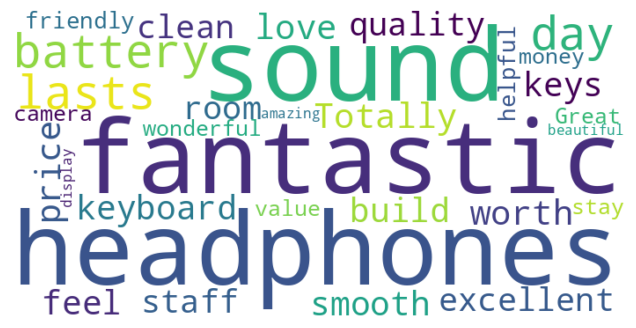

In [24]:
from wordcloud import WordCloud

positive_reviews = [r for r in reviews if classify(TextBlob(r).sentiment.polarity) == "Positive"]
print(len(positive_reviews), "positive reviews")

cloud = WordCloud(width=700, height=350, background_color="white", stopwords=STOP).generate(" ".join(positive_reviews))

plt.figure(figsize=(8, 4))
plt.imshow(cloud, interpolation="bilinear")
plt.axis("off")
plt.show()

**Result:** 4 reviews are Positive, 2 Negative and 2 Neutral, using the thresholds above.

- **Polarity** ranges from -0.65 (the late, damaged delivery) to 0.75 (the great-value camera review). The two factual reviews score exactly 0.0.
- **Subjectivity** is 0.0 for the factual reviews and between 0.47 and 0.88 for the opinion reviews, so it separates opinions from facts.
- **Word cloud:** every word in the four positive reviews occurs once, so the words are drawn at similar sizes and there is no dominant term.
- **Limitation:** TextBlob is lexicon based and does not understand negation or sarcasm, so a phrase like "nothing special" can still score as positive.

# Question 6

Text generation with an LSTM.

In [25]:
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import numpy as np
import keras
from keras import layers
from keras.utils import pad_sequences
from tf_keras.preprocessing.text import Tokenizer

keras.utils.set_random_seed(42)

training_text = (
    "cricket is a game of patience and skill. "
    "the batsman watches the ball and plays a straight drive. "
    "the bowler runs in and bowls a fast ball. "
    "the fielder dives and takes a brilliant catch. "
    "the captain sets the field and the team plays together. "
    "every player works hard in the nets before the match. "
    "the crowd cheers when the batsman hits a six. "
    "the umpire raises a finger and the bowler celebrates the wicket. "
    "a good team wins the match with teamwork and discipline. "
    "after the match the players shake hands and thank the crowd."
)

I0000 00:00:1793127056.481075  133725 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1793127058.365140  133725 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


### 1. Tokenize with Keras `Tokenizer`

Keras 3 removed `keras.preprocessing.text`, so `Tokenizer` is imported from the `tf_keras` package, where the same class still lives.

In [26]:
tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])
vocab_size = len(tokenizer.word_index) + 1

print("Vocabulary size:", vocab_size)
tokenizer.word_index

Vocabulary size: 58


{'the': 1,
 'and': 2,
 'a': 3,
 'match': 4,
 'batsman': 5,
 'ball': 6,
 'plays': 7,
 'bowler': 8,
 'in': 9,
 'team': 10,
 'crowd': 11,
 'cricket': 12,
 'is': 13,
 'game': 14,
 'of': 15,
 'patience': 16,
 'skill': 17,
 'watches': 18,
 'straight': 19,
 'drive': 20,
 'runs': 21,
 'bowls': 22,
 'fast': 23,
 'fielder': 24,
 'dives': 25,
 'takes': 26,
 'brilliant': 27,
 'catch': 28,
 'captain': 29,
 'sets': 30,
 'field': 31,
 'together': 32,
 'every': 33,
 'player': 34,
 'works': 35,
 'hard': 36,
 'nets': 37,
 'before': 38,
 'cheers': 39,
 'when': 40,
 'hits': 41,
 'six': 42,
 'umpire': 43,
 'raises': 44,
 'finger': 45,
 'celebrates': 46,
 'wicket': 47,
 'good': 48,
 'wins': 49,
 'with': 50,
 'teamwork': 51,
 'discipline': 52,
 'after': 53,
 'players': 54,
 'shake': 55,
 'hands': 56,
 'thank': 57}

### 2. Input sequences and model

In [27]:
sequences = []
for line in training_text.split("."):
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        sequences.append(token_list[: i + 1])

max_len = max(len(s) for s in sequences)
sequences = pad_sequences(sequences, maxlen=max_len, padding="pre")

X, y = sequences[:, :-1], sequences[:, -1]
print("Training sequences:", X.shape, " Labels:", y.shape)

Training sequences: (86, 10)  Labels: (86,)


In [28]:
model = keras.Sequential([
    layers.Input(shape=(max_len - 1,)),
    layers.Embedding(vocab_size, 32),
    layers.LSTM(64),
    layers.Dense(vocab_size, activation="softmax"),
])
model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 10, 32)         │         1,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 58)             │         3,770 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,458 (118.98 KB)

 Trainable params: 30,458 (118.98 KB)

 Non-trainable params: 0 (0.00 B)

### 3. Train and generate text

In [29]:
history = model.fit(X, y, epochs=300, verbose=0)
print("Final loss    :", round(history.history["loss"][-1], 4))
print("Final accuracy:", round(history.history["accuracy"][-1], 4))

Final loss    : 0.2275
Final accuracy: 0.9419


In [30]:
index_word = {i: w for w, i in tokenizer.word_index.items()}


def generate_text(seed_word, n_words=8):
    text = seed_word
    for _ in range(n_words):
        token_list = tokenizer.texts_to_sequences([text])[0]
        token_list = pad_sequences([token_list], maxlen=max_len - 1, padding="pre")
        predicted = int(np.argmax(model.predict(token_list, verbose=0), axis=-1)[0])
        text += " " + index_word.get(predicted, "")
    return text


for seed in ["cricket", "the", "a"]:
    print(generate_text(seed))

cricket is a game of patience and skill catch


the batsman watches the ball and plays a straight


a good team wins the match with teamwork and


**Result:** The Tokenizer found 58 distinct words in the 96-word training text, which gave 86 input sequences. After 300 epochs the model reached about 94% accuracy (loss about 0.23).

The three generated lines start from the seeds `cricket`, `the` and `a`. They look like the training sentences (`the batsman watches the ball and plays a straight`) and drift after a few words (`cricket is a game of patience and skill catch`). That happens because the training set is tiny: the model largely memorizes its sentences, and `argmax` always picks the single most likely next word. A larger corpus and sampling with a temperature would give more varied text.